# XEUS-R

In [1]:
R.version

               _                           
platform       wasm32-unknown-emscripten   
arch           wasm32                      
os             emscripten                  
system         wasm32, emscripten          
status                                     
major          4                           
minor          5.3                         
year           2026                        
month          03                          
day            11                          
svn rev        89597                       
language       R                           
version.string R version 4.5.3 (2026-03-11)
nickname       Reassured Reassurer         

## Internal packages

In [2]:
library(stats)

set.seed(123)
x <- rnorm(100)
y <- 2 * x + rnorm(100)

# Linear regression
model <- lm(y ~ x)
summary(model)


Call:
lm(formula = y ~ x)

Residuals:
    Min      1Q  Median      3Q     Max 
-1.9073 -0.6835 -0.0875  0.5806  3.2904 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept) -0.10280    0.09755  -1.054    0.295    
x            1.94753    0.10688  18.222   <2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.9707 on 98 degrees of freedom
Multiple R-squared:  0.7721,	Adjusted R-squared:  0.7698 
F-statistic:   332 on 1 and 98 DF,  p-value: < 2.2e-16


In [3]:
A <- matrix(c(1, 2, 3, 4, 5, 6), nrow = 3, ncol = 2)

# Singular value decomposition
svd_result <- La.svd(A)

print(svd_result)

$d
[1] 9.5080320 0.7728696

$u
           [,1]       [,2]
[1,] -0.4286671  0.8059639
[2,] -0.5663069  0.1123824
[3,] -0.7039467 -0.5811991

$vt
           [,1]       [,2]
[1,] -0.3863177 -0.9223658
[2,] -0.9223658  0.3863177



In [4]:
A <- matrix(c(4, 1, 1, 3), nrow = 2, byrow = TRUE)

# Eigen decomposition
eigen_result <- eigen(A)

print(eigen_result$values)

print(eigen_result$vectors)

[1] 4.618034 2.381966
           [,1]       [,2]
[1,] -0.8506508  0.5257311
[2,] -0.5257311 -0.8506508


In [5]:
# Example positive-definite matrix
A <- matrix(c(4, 1, 1, 3), nrow = 2, byrow = TRUE)

# Cholesky decomposition
chol_result <- chol(A)

print(chol_result)

     [,1]     [,2]
[1,]    2 0.500000
[2,]    0 1.658312


In [6]:
B <- matrix(c(1, 2, 3, 4, 5, 6), nrow = 3, ncol = 2)
C <- matrix(c(7, 8, 9, 10, 11, 12), nrow = 3, ncol = 2)

# Perform matrix multiplication using BLAS
result <- crossprod(B, C)

print(result)

     [,1] [,2]
[1,]   50   68
[2,]  122  167


In [7]:
# Fibonacci sequence
fibonacci_loop <- function(n) {
    a <- 0
    b <- 1

    for (i in 1:n) {
        fib <- a
        cat(fib, "\n")
        a <- b
        b <- fib + b
    }
    return(a)
}

fibonacci_loop(10)

0 
1 
1 
2 
3 
5 
8 
13 
21 
34 


[1] 55

## Plotting

Some of the following R Code was pulled from https://www.statmethods.net/advgraphs/ggplot2.html, and updated to use newer `ggplot2` APIs.

In [ ]:
grafik1 <- ggplot(mtcars, aes(x = mpg, fill = gear)) +
  geom_density(alpha = 0.5) +
  labs(
    title = "Distribution of Gas Milage",
    x = "Miles Per Gallon",
    y = "Density",
    fill = "Gears"
  )

print(grafik1)

ggsave(
  filename = "grafik1.png",
  plot = grafik1,
  width = 8,
  height = 5,
  dpi = 300
)

In [9]:
# create factors with value labels
mtcars$gear <- factor(mtcars$gear,levels=c(3,4,5),
  	labels=c("3gears","4gears","5gears"))
mtcars$am <- factor(mtcars$am,levels=c(0,1),
  	labels=c("Automatic","Manual"))
mtcars$cyl <- factor(mtcars$cyl,levels=c(4,6,8),
   labels=c("4cyl","6cyl","8cyl"))

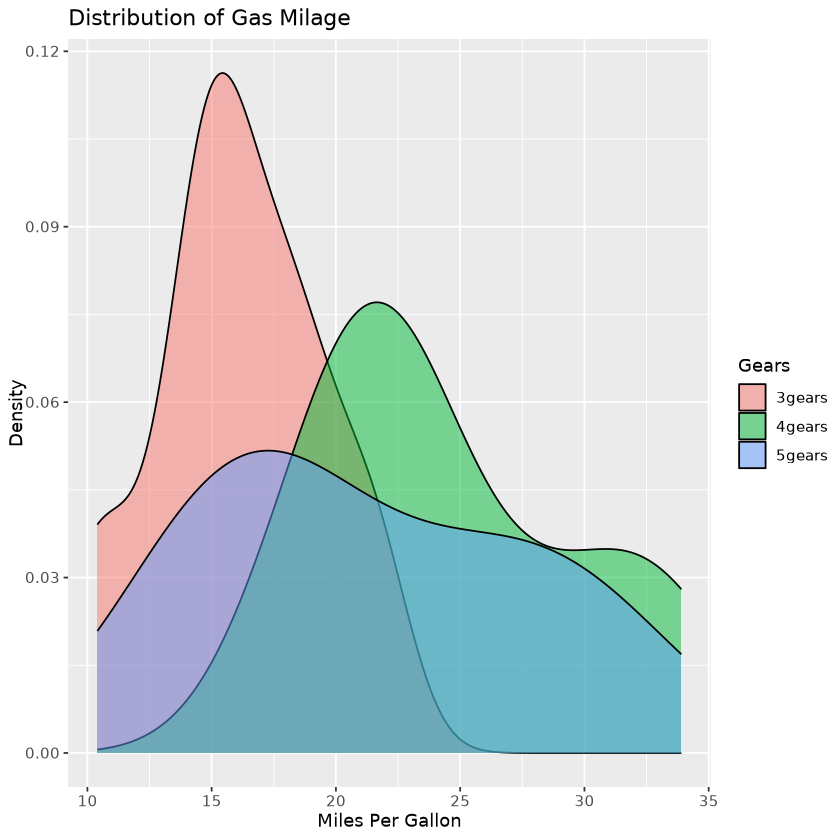

In [10]:
# Kernel density plots for mpg
# grouped by number of gears (indicated by color)
ggplot(mtcars, aes(x = mpg, fill = gear)) +
  geom_density(alpha = 0.5) +
  labs(
    title = "Distribution of Gas Milage",
    x = "Miles Per Gallon",
    y = "Density",
    fill = "Gears"
  )

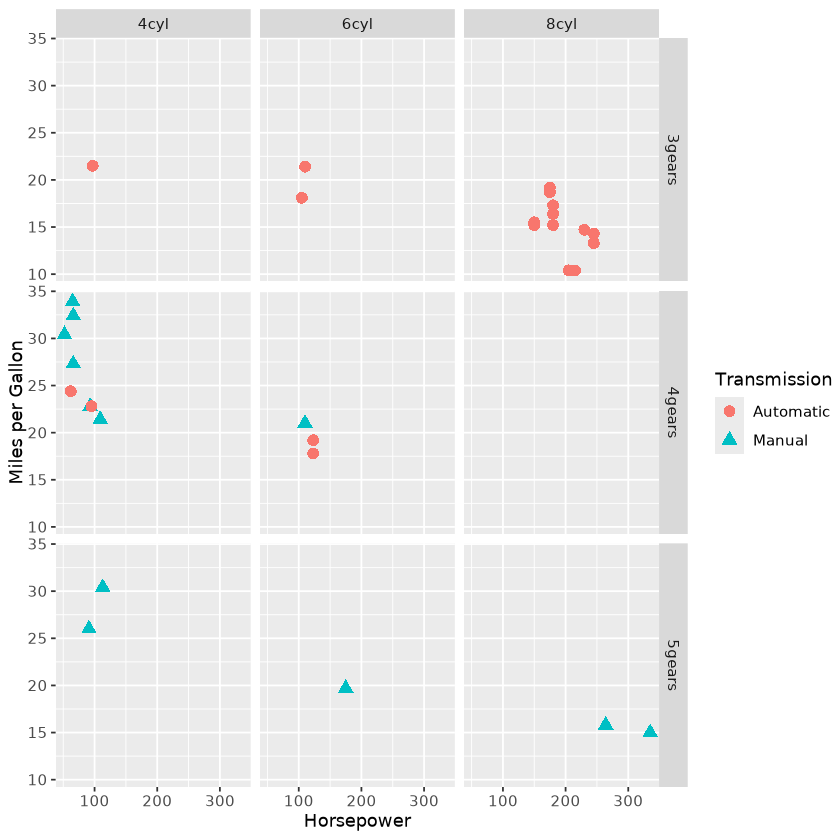

In [11]:
# Scatterplot of mpg vs. hp for each combination of gears and cylinders
# in each facet, transmission type is represented by shape and color
ggplot(mtcars, aes(x = hp, y = mpg, shape = am, color = am)) +
  geom_point(size = 3) +
  facet_grid(gear ~ cyl) +
  labs(
    x = "Horsepower",
    y = "Miles per Gallon",
    shape = "Transmission",
    color = "Transmission"
  )

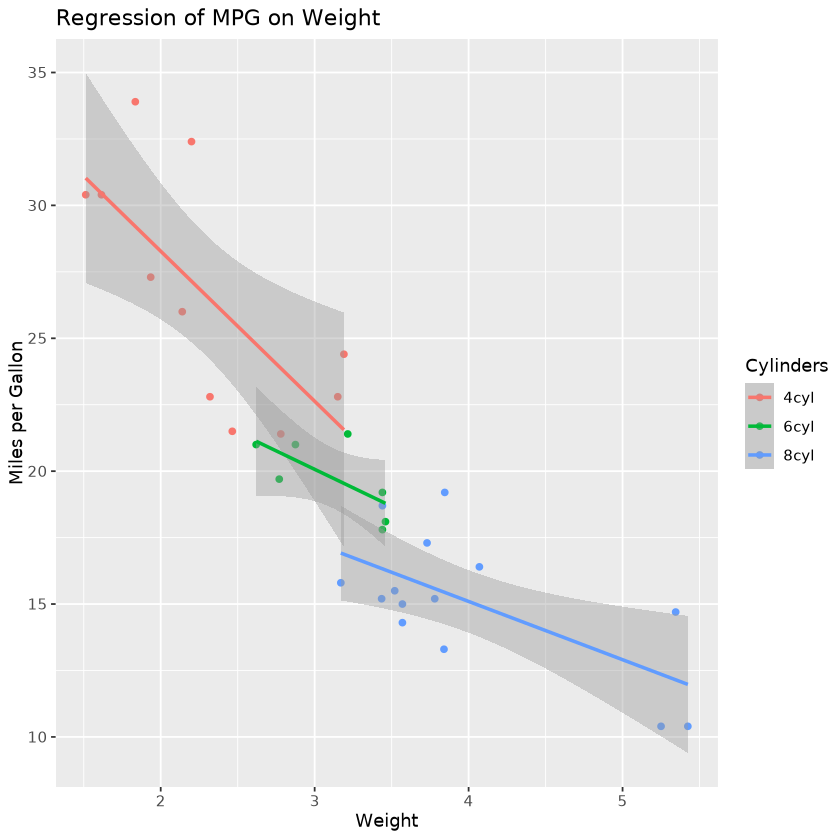

In [12]:
# Separate regressions of mpg on weight for each number of cylinders
ggplot(mtcars, aes(x = wt, y = mpg, color = cyl)) +
  geom_point() +
  geom_smooth(method = "lm", formula = y ~ x) +
  labs(
    title = "Regression of MPG on Weight",
    x = "Weight",
    y = "Miles per Gallon",
    color = "Cylinders"
  )

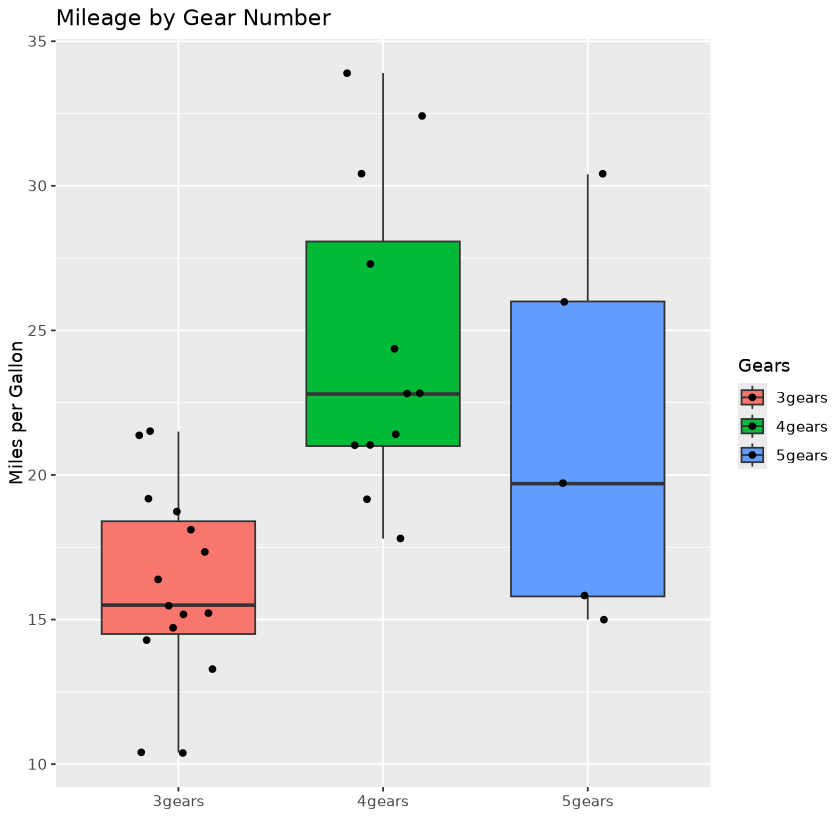

In [13]:
# Boxplots of mpg by number of gears
# observations (points) are overlayed and jittered
ggplot(mtcars, aes(x = gear, y = mpg, fill = gear)) +
  geom_boxplot() +
  geom_jitter(width = 0.2) +
  labs(
    title = "Mileage by Gear Number",
    x = "",
    y = "Miles per Gallon",
    fill = "Gears"
  )

## Other R Packages

In [14]:
library(RColorBrewer)
palette <- brewer.pal(8, "Set3")
print(palette)

[1] "#8DD3C7" "#FFFFB3" "#BEBADA" "#FB8072" "#80B1D3" "#FDB462" "#B3DE69"
[8] "#FCCDE5"


In [15]:
library(crayon)

# Create colorful text
red_text <- red("This is red text")
green_text <- green("This is green text")
blue_text <- blue("This is blue text")
bold_text <- bold("This is bold text")
underline_text <- underline("This is underlined text")

cat(red_text, "\n")
cat(green_text, "\n")
cat(blue_text, "\n")
cat(bold_text, "\n")
cat(underline_text, "\n")


Attaching package: ‘crayon’

The following object is masked from ‘package:ggplot2’:

    %+%



This is red text 
This is green text 
This is blue text 
This is bold text 
This is underlined text 


In [16]:
library(htmltools)

# Create HMTL elements
title <- tags$title("My HTML Page")
header <- tags$h1("Hello there!")
paragraph <- tags$p("This is a paragraph created using htmltools.")
list_items <- tags$ul(tags$li("Item 1"), tags$li("Item 2"), tags$li("Item 3"))

# Combine elements into an HTML document
html_doc <- tags$html(
    tags$head(title),
    tags$body(
        header,
        paragraph,
        list_items
    )
)

print(html_doc)

<html>
  <body>
    <h1>Hello there!</h1>
    <p>This is a paragraph created using htmltools.</p>
    <ul>
      <li>Item 1</li>
      <li>Item 2</li>
      <li>Item 3</li>
    </ul>
  </body>
</html>


In [17]:
library(farver)

# Define a color in RBG space
rgb_color <- matrix(c(255, 0, 0), ncol = 3)

# Convert RGB to HSV
hsv_color <- convert_colour(rgb_color, "rgb", "hsv")

# Convert RGB to LAB
lab_color <- convert_colour(rgb_color, "rgb", "lab")

print(rgb_color)
print(hsv_color)
print(lab_color)

     [,1] [,2] [,3]
[1,]  255    0    0
     h s v
[1,] 0 1 1
            l        a        b
[1,] 53.24079 80.09796 67.20432
